# Ejercicio 10: Aplicación final a una imagen desconocida

En este ejercicio reconstruimos una imagen desconocida de $128\times128$ píxeles a partir de mediciones tomográficas con ruido. Primero organizamos las mediciones en un sinograma y luego comparamos reconstrucciones sin regularización y con distintos valores de $\lambda$, utilizando una matriz de diferencias para controlar la suavidad de la imagen.

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from cargar_datos_tomografia import cargar_datos_tomografia
from scipy.sparse import lil_matrix

## a) Carga y dimensiones de los datos

Cargamos los datos de la tomografía y determinamos la cantidad de ángulos $K$ y de posiciones del detector $q$. Luego verificamos las dimensiones de la matriz $A$ y del vector de mediciones $b$.

In [14]:
# cargamos los datos
datos = cargar_datos_tomografia("datos_tomografia_final_128.npz")

# recuperamos los datos que vamos a utilizar
A = datos["A"]
b = datos["b"]
n = datos["n"]
angulos = datos["angulos"]
posiciones_detector = datos["posiciones_detector"]

# calculamos K y q
K = len(angulos)
q = len(posiciones_detector)

# mostramos y verificamos los resultados
print("K =", K, "y q =", q)
print("Dimensiones de A:", A.shape, "- Dimensiones de b:", b.shape)
print("¿Las dimensiones son correctas?", A.shape == (K * q, n**2) and b.shape == (K * q,))

K = 90 y q = 183
Dimensiones de A: (16470, 16384) - Dimensiones de b: (16470,)
¿Las dimensiones son correctas? True


Obtuvimos $K=90$ ángulos y $q=183$ posiciones del detector, por lo que contamos con $Kq=16470$ mediciones. También verificamos que $A\in\mathbb{R}^{16470\times16384}$ y que $b\in\mathbb{R}^{16470}$, por lo que las dimensiones coinciden con una imagen de $128\times128$ píxeles.

## b) Construcción y visualización del sinograma

Organizamos las mediciones del vector $b$ en una matriz $S$ de dimensiones $K\times q$. Cada fila contiene las mediciones correspondientes a un ángulo y cada columna corresponde a una posición del detector.

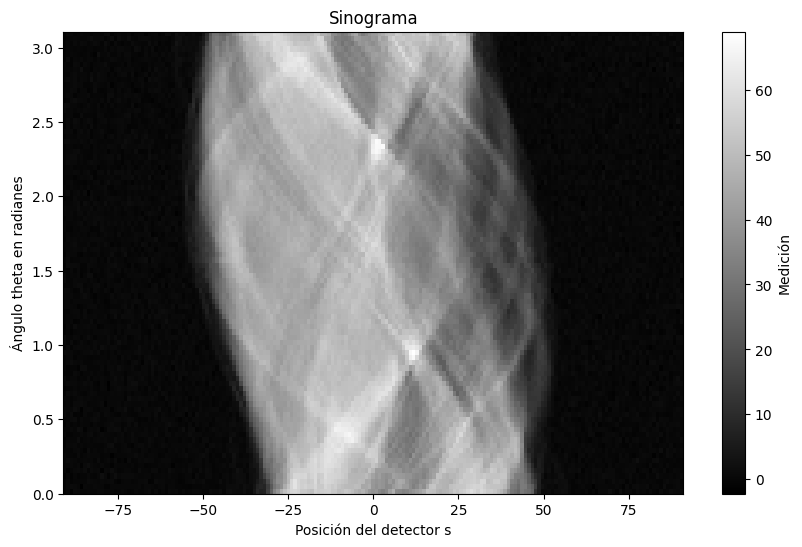

In [15]:
# organizamos las mediciones en una matriz
S = b.reshape(K, q)

# visualizamos el sinograma
plt.figure(figsize=(10, 6))

plt.imshow(
    S,
    cmap="gray",
    aspect="auto",
    origin="lower",
    extent=[
        posiciones_detector[0],
        posiciones_detector[-1],
        angulos[0],
        angulos[-1]
    ]
)

plt.colorbar(label="Medición")
plt.xlabel("Posición del detector s")
plt.ylabel("Ángulo theta en radianes")
plt.title("Sinograma")
plt.show()

Obtuvimos un sinograma de dimensiones $90\times183$. Cada fila representa las mediciones tomadas desde un ángulo y cada columna corresponde a una posición del detector. Las variaciones de intensidad muestran cómo cambia la atenuación registrada según el ángulo y la posición del rayo.

## c) Construcción de la matriz de diferencias dispersa

Construimos la matriz $D$, que calcula las diferencias entre píxeles vecinos en las direcciones horizontal y vertical. Como cada fila compara solamente dos píxeles, la almacenamos como una matriz dispersa.

In [16]:
def matriz_diferencias(n):
    # calculamos la cantidad total de diferencias
    cantidad_filas = 2 * n * (n - 1)

    # creamos una matriz dispersa
    D = lil_matrix((cantidad_filas, n**2))

    fila = 0

    # diferencias entre píxeles vecinos horizontales
    for i in range(n):
        for j in range(n - 1):
            k = i * n + j

            D[fila, k] = -1
            D[fila, k + 1] = 1

            fila += 1

    # diferencias entre píxeles vecinos verticales
    for i in range(n - 1):
        for j in range(n):
            k = i * n + j

            D[fila, k] = -1
            D[fila, k + n] = 1

            fila += 1

    # convertimos la matriz a un formato eficiente para los cálculos
    return D.tocsr()

D = matriz_diferencias(n)

print("Dimensiones de D:", D.shape)
print("¿Cada fila tiene dos valores no nulos?", np.all(D.getnnz(axis=1) == 2))

Dimensiones de D: (32512, 16384)
¿Cada fila tiene dos valores no nulos? True


La matriz $D$ tiene dimensiones $32512\times16384$, coincidiendo con las $2n(n-1)$ diferencias horizontales y verticales posibles. También verificamos que cada fila tiene exactamente dos valores no nulos, ya que cada diferencia compara dos píxeles vecinos.

## d) Reconstrucción sin regularización

Reconstruimos la imagen mediante gradiente descendiente utilizando solamente el ajuste a las mediciones. En este caso usamos $\lambda=0$, por lo que no penalizamos las diferencias entre píxeles vecinos.

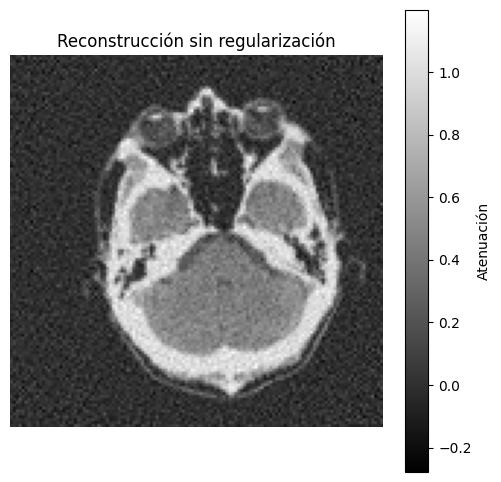

In [ ]:
def gradiente_descendiente(A, b, alpha, max_iter):
    # comenzamos con una imagen formada por ceros
    x = np.zeros(A.shape[1])

    for iteracion in range(max_iter):
        # calculamos la diferencia entre las mediciones estimadas y las recibidas
        residuo = A @ x - b

        # calculamos el gradiente
        gradiente = A.T @ residuo

        # actualizamos la reconstrucción
        x = x - alpha * gradiente

    return x


# elegimos el paso y la cantidad de iteraciones
alpha = 0.0001
max_iter = 500

# reconstruimos la imagen sin regularización
x_sin_regularizar = gradiente_descendiente(A, b, alpha, max_iter)

# recuperamos la forma matricial
X_sin_regularizar = x_sin_regularizar.reshape(n, n)

# visualización

plt.figure(figsize=(6, 6))

plt.imshow(X_sin_regularizar, cmap="gray")
plt.colorbar(label="Atenuación")
plt.title("Reconstrucción sin regularización")
plt.axis("off")

plt.show()

Obtuvimos una primera reconstrucción utilizando solamente el ajuste a las mediciones. Como no aplicamos regularización, la imagen puede reproducir parte del ruido presente en los datos y presentar variaciones bruscas entre píxeles vecinos.

## e) Reconstrucciones con regularización

Realizamos reconstrucciones utilizando diferentes valores de $\lambda$. La regularización busca reducir las variaciones bruscas entre píxeles vecinos y disminuir el efecto del ruido.

In [19]:
def gradiente_descendiente_regularizado(A, b, D, lamb, alpha, max_iter):
    # comenzamos con una imagen formada por ceros
    x = np.zeros(A.shape[1])

    for iteracion in range(max_iter):
        # calculamos el residuo
        residuo = A @ x - b

        # calculamos el gradiente del costo regularizado
        gradiente = A.T @ residuo + lamb * D.T @ (D @ x)

        # actualizamos la reconstrucción
        x = x - alpha * gradiente

    return x


# definimos los valores de lambda
lambdas = [0.1, 1, 10, 30, 100]

# acá guardamos las reconstrucciones
reconstrucciones = {}

for lamb in lambdas:
    # calculamos la reconstrucción para este valor de lambda
    x_rec = gradiente_descendiente_regularizado(A, b, D, lamb, alpha, max_iter)

    # guardamos el resultado
    reconstrucciones[lamb] = x_rec

## f) Comparación numérica de las reconstrucciones

Para cada valor de $\lambda$, calculamos la norma del residuo, la variación de la imagen y sus valores mínimo y máximo. También comparamos los residuos con la norma esperada del ruido.

In [20]:
# recuperamos la norma esperada del ruido
norma_ruido_esperada = datos["norma_ruido_esperada"]

print("Norma esperada del ruido:", norma_ruido_esperada)

Norma esperada del ruido: 75.96688842773438


In [21]:
# agregamos la reconstrucción sin regularización
reconstrucciones[0] = x_sin_regularizar

# ordenamos los valores de lambda
lambdas_completos = [0, 0.1, 1, 10, 30, 100]

# acá guardamos las medidas calculadas
metricas = {}

print("RESULTADOS DE LAS RECONSTRUCCIONES")
print()
print("{:<10} {:<10} {:<12} {:<15} {:<15} {:<12} {:<12}".format(
    "lambda", "alpha", "iteraciones", "residuo", "variación", "mínimo", "máximo"
))
print("-" * 90)

for lamb in lambdas_completos:
    # recuperamos la reconstrucción
    x_rec = reconstrucciones[lamb]

    # calculamos el residuo
    residuo = A @ x_rec - b
    norma_residuo = np.linalg.norm(residuo)

    # calculamos la variación entre píxeles vecinos
    norma_variacion = np.linalg.norm(D @ x_rec)

    # calculamos los valores mínimo y máximo
    valor_minimo = x_rec.min()
    valor_maximo = x_rec.max()

    # guardamos las medidas
    metricas[lamb] = {
        "residuo": norma_residuo,
        "variacion": norma_variacion,
        "minimo": valor_minimo,
        "maximo": valor_maximo
    }

    print("{:<10} {:<10.4f} {:<12} {:<15.4f} {:<15.4f} {:<12.4f} {:<12.4f}".format(
        lamb,
        alpha,
        max_iter,
        norma_residuo,
        norma_variacion,
        valor_minimo,
        valor_maximo
    ))

RESULTADOS DE LAS RECONSTRUCCIONES

lambda     alpha      iteraciones  residuo         variación       mínimo       máximo      
------------------------------------------------------------------------------------------
0          0.0001     1000         45.5616         25.3974         -0.2780      1.1990      
0.1        0.0001     1000         45.6416         25.1695         -0.2737      1.1958      
1          0.0001     1000         46.4450         23.5666         -0.2413      1.1723      
10         0.0001     1000         55.4015         18.4941         -0.1504      1.1081      
30         0.0001     1000         71.5299         15.1217         -0.1041      1.0769      
100        0.0001     1000         102.6255        11.4692         -0.0627      1.0505      


## g) Comparación visual y elección de la reconstrucción

Comparamos el sinograma, la reconstrucción sin regularización y tres reconstrucciones regularizadas. Utilizamos la misma escala de grises para todas las reconstrucciones, lo que permite comparar sus valores de manera directa.

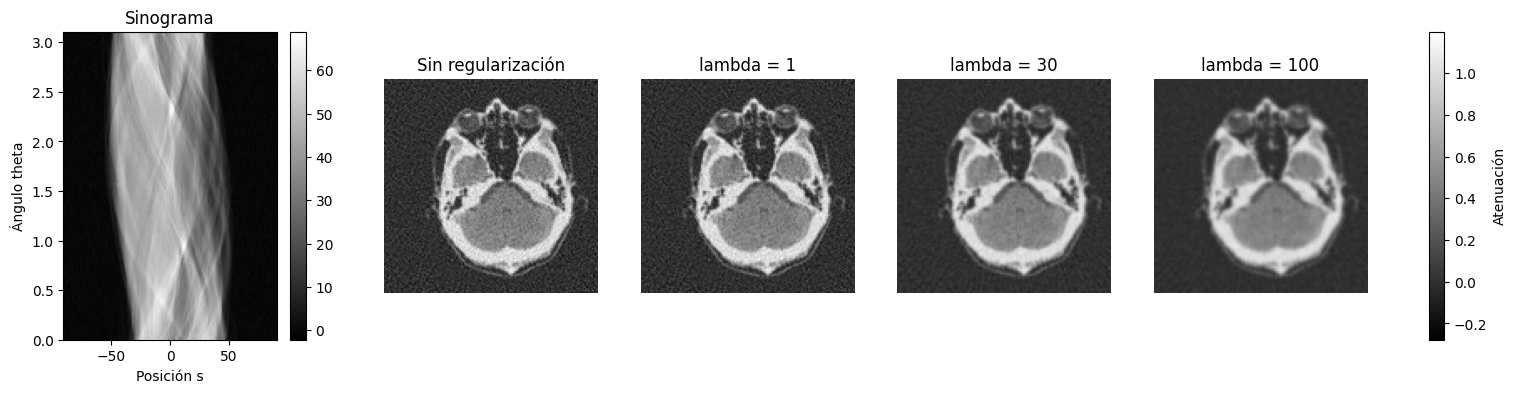

In [22]:
# seleccionamos las reconstrucciones que vamos a comparar
imagenes = [x_sin_regularizar, reconstrucciones[1], reconstrucciones[30], reconstrucciones[100]]

titulos = ["Sin regularización", "lambda = 1", "lambda = 30", "lambda = 100"]

# calculamos una escala común para todas las reconstrucciones
valores = np.concatenate(imagenes)
vmin = valores.min()
vmax = valores.max()

# creamos la figura
fig, axes = plt.subplots(1, 5, figsize=(20, 4))

# mostramos el sinograma
im0 = axes[0].imshow(S,
    cmap="gray",
    aspect="auto",
    origin="lower",
    extent=[
        posiciones_detector[0],
        posiciones_detector[-1],
        angulos[0],
        angulos[-1]
    ]
)

axes[0].set_title("Sinograma")
axes[0].set_xlabel("Posición s")
axes[0].set_ylabel("Ángulo theta")
fig.colorbar(im0, ax=axes[0])

# mostramos las reconstrucciones
for i in range(len(imagenes)):
    X_rec = imagenes[i].reshape(n, n)

    im = axes[i + 1].imshow(
        X_rec,
        cmap="gray",
        vmin=vmin,
        vmax=vmax
    )

    axes[i + 1].set_title(titulos[i])
    axes[i + 1].axis("off")

# agregamos una escala común
fig.colorbar(im, ax=axes[1:], label="Atenuación")

plt.show()

### Elección de la reconstrucción

Elegimos la reconstrucción con $\lambda=30$. Su residuo es $71.53$, el valor más cercano a la norma esperada del ruido, que es aproximadamente $75.97$. Esto indica que la reconstrucción explica las mediciones sin intentar ajustar completamente el ruido.

Además, presenta una variación menor que las reconstrucciones con valores bajos de $\lambda$, reduciendo cambios bruscos entre píxeles vecinos. Al mismo tiempo, conserva mejor la estructura de la imagen que la reconstrucción con $\lambda=100$, donde el suavizado es más intenso. Por estas razones, consideramos que $\lambda=30$ ofrece el mejor equilibrio entre el ajuste a las mediciones y la suavidad de la imagen.